# MarineGuard AI | Dataset Validation and Source Audit

**Objective.** Assess the provenance, annotation consistency, and evaluation limitations of the datasets considered during MarineGuard AI model development. The audit was performed after the initial model evaluations to investigate the narrow Net validation sample and cross-source transfer.

**Scope.** Prepared SeaClear/MarineGuard data, source SeaClear COCO annotations, a preliminary camera-holdout proposal, and a candidate Roboflow fishing-net dataset. The notebook records investigative analyses; it does **not** retrain the selected model or define the final application dataset.

**Reproducibility.** Paths refer to the original Google Drive/Colab workspace. Code and saved outputs are retained from the original notebook. Some exploratory cells depend on artifacts produced in earlier sessions and should be read in sequence with the experiment history.


## 01 | Prepared-dataset composition

Audit the original train and validation directories for image counts, Net and Rope instances, background frames, and missing annotation files.


In [2]:
from google.colab import drive
from pathlib import Path
from collections import Counter
import pandas as pd

drive.mount("/content/drive")

ROOT = Path(
    "/content/drive/MyDrive/MarineGuard_YOLO/"
    "MarineGuard_YOLO_Fixed"
)

image_ext = {".jpg", ".jpeg", ".png", ".webp"}

for split in ["train", "val"]:
    image_dir = ROOT / "images" / split
    label_dir = ROOT / "labels" / split

    images = sorted(
        p for p in image_dir.rglob("*")
        if p.suffix.lower() in image_ext
    )

    counts = Counter()
    backgrounds = 0
    missing = 0

    for image in images:
        label = label_dir / f"{image.stem}.txt"

        if not label.exists():
            missing += 1
            continue

        lines = [
            line for line in label.read_text().splitlines()
            if line.strip()
        ]

        if not lines:
            backgrounds += 1

        for line in lines:
            cls = int(line.split()[0])
            counts[cls] += 1

    print(f"\n--- {split.upper()} ---")
    print("Images:", len(images))
    print("Net instances:", counts[0])
    print("Rope instances:", counts[1])
    print("Backgrounds:", backgrounds)
    print("Missing labels:", missing)

    print("\nExample filenames:")
    for image in images[:15]:
        print(" ", image.name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

--- TRAIN ---
Images: 2626
Net instances: 1067
Rope instances: 2055
Backgrounds: 500
Missing labels: 0

Example filenames:
  100.jpg
  1027.jpg
  1028.jpg
  1029.jpg
  1030.jpg
  1031.jpg
  1032.jpg
  1033.jpg
  1034.jpg
  1035.jpg
  1036.jpg
  1037.jpg
  1038.jpg
  1039.jpg
  1040.jpg

--- VAL ---
Images: 178
Net instances: 7
Rope instances: 71
Backgrounds: 100
Missing labels: 0

Example filenames:
  2021_09_16_16_15_03_Front_07-33-11.jpg
  2021_09_16_16_15_03_Front_07-33-18.jpg
  2021_09_16_16_15_03_Front_07-33-25.jpg
  2021_09_16_16_15_03_Front_07-34-02.jpg
  2021_09_16_16_15_03_Front_07-59-01.jpg
  2021_09_16_16_15_03_Front_07-59-08.jpg
  2021_09_16_16_15_03_Front_08-46-26.jpg
  2021_09_16_16_15_03_Front_08-47-10.jpg
  2021_09_16_16_15_03_Front_08-47-17.jpg
  2021_09_16_16_15_03_Front_08-54-10.jpg
  2021_09_16_16_15_03_Front_08-55-22.jpg
  2021_09_16_16_

## 02 | Filename patterns and class distribution

Identify filename conventions associated with SeaClear, CleanSea, and additional background images. Inspect which validation frames contain Net annotations.


In [3]:
from pathlib import Path
from collections import Counter
import pandas as pd
import re

ROOT = Path(
    "/content/drive/MyDrive/MarineGuard_YOLO/"
    "MarineGuard_YOLO_Fixed"
)

rows = []

for split in ["train", "val"]:
    image_dir = ROOT / "images" / split

    for image in image_dir.iterdir():
        if image.suffix.lower() not in {
            ".jpg", ".jpeg", ".png", ".webp"
        }:
            continue

        label = ROOT / "labels" / split / f"{image.stem}.txt"

        net_count = 0
        rope_count = 0

        if label.exists():
            for line in label.read_text().splitlines():
                if not line.strip():
                    continue

                class_id = int(line.split()[0])

                if class_id == 0:
                    net_count += 1
                elif class_id == 1:
                    rope_count += 1

        if image.stem.isdigit():
            filename_type = "Numeric"
        elif image.stem.lower().startswith("cleansea"):
            filename_type = "CleanSea"
        elif image.stem.lower().startswith("bg_"):
            filename_type = "Background prefix"
        elif re.match(r"^\d{4}_\d{2}_\d{2}", image.stem):
            filename_type = "Timestamp / Camera"
        else:
            filename_type = "Other"

        rows.append({
            "split": split,
            "filename": image.name,
            "filename_type": filename_type,
            "net_instances": net_count,
            "rope_instances": rope_count
        })

df = pd.DataFrame(rows)

print("FILENAME DISTRIBUTION")
display(pd.crosstab(df["filename_type"], df["split"]))

print("\nTRAINING IMAGES CONTAINING NETS")
display(
    df[
        (df["split"] == "train") &
        (df["net_instances"] > 0)
    ].head(30)
)

print("\nVALIDATION IMAGES CONTAINING NETS")
display(
    df[
        (df["split"] == "val") &
        (df["net_instances"] > 0)
    ]
)

FILENAME DISTRIBUTION


split,train,val
filename_type,,
Background prefix,300,0
CleanSea,193,0
Numeric,2112,18
Other,0,72
Timestamp / Camera,21,88



TRAINING IMAGES CONTAINING NETS


,split,filename,filename_type,net_instances,rope_instances
1,train,2791.jpg,Numeric,1,0
2,train,2792.jpg,Numeric,1,0
3,train,2823.jpg,Numeric,1,0
4,train,2871.jpg,Numeric,3,0
5,train,2873.jpg,Numeric,2,0
8,train,2793.jpg,Numeric,1,0
9,train,283.jpg,Numeric,1,0
11,train,2827.jpg,Numeric,1,1
13,train,2912.jpg,Numeric,1,1
14,train,2914.jpg,Numeric,1,1



VALIDATION IMAGES CONTAINING NETS


,split,filename,filename_type,net_instances,rope_instances
2636,val,2021_09_16_17_00_17_Front_fixed_twice_07-37-03...,Timestamp / Camera,1,0
2645,val,2021_09_16_17_00_17_Front_fixed_twice_07-36-19...,Timestamp / Camera,1,0
2656,val,2021_09_16_17_00_17_Front_fixed_twice_07-36-26...,Timestamp / Camera,1,0
2678,val,2021_09_16_17_00_17_Front_fixed_twice_07-36-12...,Timestamp / Camera,1,0
2682,val,2021_09_16_17_00_17_Front_fixed_twice_07-37-10...,Timestamp / Camera,1,0
2770,val,2021_09_16_17_00_17_Front_fixed_twice_07-37-17...,Timestamp / Camera,1,0
2776,val,2021_09_16_17_00_17_Front_fixed_twice_07-37-24...,Timestamp / Camera,1,0


## 03 | Provisional recording-group inspection

Trace the seven validation Net annotations to their recording identifiers and locate source metadata. Filename-based grouping at this stage is preliminary.


In [4]:
from pathlib import Path
from collections import Counter
import re

ROOT = Path(
    "/content/drive/MyDrive/MarineGuard_YOLO/MarineGuard_YOLO_Fixed"
)
DRIVE = Path("/content/drive/MyDrive")

def get_recording_group(filename):
    stem = Path(filename).stem

    # Numeric names cannot yet be assigned to a recording.
    if stem.isdigit():
        return "UNKNOWN_NUMERIC"

    if stem.lower().startswith("cleansea"):
        return "CLEANSEA"

    if stem.lower().startswith("bg_"):
        return "BACKGROUND"

    # Remove the final frame timestamp, e.g. _07-37-03
    match = re.match(
        r"^(.+)_\d{2}-\d{2}-\d{2}$",
        stem
    )

    if match:
        return match.group(1)

    return "UNKNOWN_OTHER"

# 1. Inspect Net-containing validation groups
groups = Counter()

for image in (ROOT / "images/val").iterdir():
    if image.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        continue

    label = ROOT / "labels/val" / f"{image.stem}.txt"

    if not label.exists():
        continue

    net_count = sum(
        line.split()[0] == "0"
        for line in label.read_text().splitlines()
        if line.strip()
    )

    if net_count:
        groups[get_recording_group(image.name)] += net_count

print("NET INSTANCES BY PROVISIONAL RECORDING GROUP:")
for group, count in groups.most_common():
    print(f"{count:3} Nets | {group}")

# 2. Find possible source metadata in Google Drive
print("\nPOSSIBLE ORIGINAL METADATA FILES:")

candidates = []

for p in DRIVE.rglob("*"):
    if not p.is_file():
        continue

    if p.suffix.lower() not in {".json", ".csv"}:
        continue

    name = p.name.lower()
    parent = str(p.parent).lower()

    if (
        any(x in name for x in [
            "annotation", "dataset", "mapping",
            "metadata", "instance", "seaclear"
        ])
        or "seaclear" in parent
    ):
        candidates.append(p)

for p in candidates[:50]:
    print(p)

print("\nTotal metadata candidates:", len(candidates))

NET INSTANCES BY PROVISIONAL RECORDING GROUP:
  7 Nets | 2021_09_16_17_00_17_Front_fixed_twice

POSSIBLE ORIGINAL METADATA FILES:
/content/drive/MyDrive/MarineGuard_Ablation_NoCleanSea_YOLO26n_v1/old_dataset_audit.csv

Total metadata candidates: 1


## 04 | Previous dataset-audit artifact

Inspect an earlier no-CleanSea dataset audit for context. Its figures describe a separate dataset variant, not the final verified training directory.


In [5]:
import pandas as pd
from pathlib import Path

CSV = Path(
    "/content/drive/MyDrive/"
    "MarineGuard_Ablation_NoCleanSea_YOLO26n_v1/"
    "old_dataset_audit.csv"
)

df = pd.read_csv(CSV)

print("Columns:")
print(df.columns.tolist())

print("\nNumber of rows:", len(df))

print("\nFirst 10 rows:")
display(df.head(10))

print("\nSample values:")
for column in df.columns:
    print(f"{column}: {df[column].dropna().head(3).tolist()}")

Columns:
['split', 'images', 'Net', 'Rope', 'backgrounds', 'Net_boxes_95pct_plus', 'Rope_boxes_95pct_plus', 'issues']

Number of rows: 3

First 10 rows:


,split,images,Net,Rope,backgrounds,Net_boxes_95pct_plus,Rope_boxes_95pct_plus,issues
0,train,2140,953,1976,207,42,0,0
1,val,178,7,71,100,0,0,0
2,test,214,101,103,0,0,0,40



Sample values:
split: ['train', 'val', 'test']
images: [2140, 178, 214]
Net: [953, 7, 101]
Rope: [1976, 71, 103]
backgrounds: [207, 100, 0]
Net_boxes_95pct_plus: [42, 0, 0]
Rope_boxes_95pct_plus: [0, 0, 0]
issues: [0, 0, 40]


## 05 | Original SeaClear source discovery

Locate the original SeaClear image archive and accompanying metadata before comparing the prepared YOLO dataset against its source.


In [8]:
from pathlib import Path

DRIVE = Path("/content/drive/MyDrive")

# Find the original dataset files
image_extensions = {".jpg", ".jpeg", ".png"}
metadata_extensions = {".json", ".csv"}

print("===== SEACLEAR FOLDERS =====")

folders = [
    p for p in DRIVE.iterdir()
    if p.is_dir() and (
        "sea" in p.name.lower()
        or "marineguard_original" in p.name.lower()
    )
]

for folder in folders:
    print(folder)

print("\n===== DATASET CONTENTS =====")

for folder in folders:
    print(f"\nFolder: {folder.name}")

    files = [p for p in folder.rglob("*") if p.is_file()]

    images = [
        p for p in files
        if p.suffix.lower() in image_extensions
    ]

    metadata = [
        p for p in files
        if p.suffix.lower() in metadata_extensions
    ]

    print("Total images:", len(images))
    print("Metadata files:", len(metadata))

    print("\nMetadata paths:")
    for p in metadata[:20]:
        print(" ", p)

    print("\nSample image paths:")
    for p in images[:15]:
        print(" ", p)

===== SEACLEAR FOLDERS =====
/content/drive/MyDrive/MarineGuard_Ablation_NoCleanSea_YOLO26n_v1
/content/drive/MyDrive/MarineGuard_YOLO_NoCleanSea_v1
/content/drive/MyDrive/MarineGuard_CleanSea_Separated_v1
/content/drive/MyDrive/MarineGuard_Original_SeaClear

===== DATASET CONTENTS =====

Folder: MarineGuard_Ablation_NoCleanSea_YOLO26n_v1
Total images: 0
Metadata files: 1

Metadata paths:
  /content/drive/MyDrive/MarineGuard_Ablation_NoCleanSea_YOLO26n_v1/old_dataset_audit.csv

Sample image paths:

Folder: MarineGuard_YOLO_NoCleanSea_v1
Total images: 239
Metadata files: 0

Metadata paths:

Sample image paths:
  /content/drive/MyDrive/MarineGuard_YOLO_NoCleanSea_v1/images/train/1033.jpg
  /content/drive/MyDrive/MarineGuard_YOLO_NoCleanSea_v1/images/train/1035.jpg
  /content/drive/MyDrive/MarineGuard_YOLO_NoCleanSea_v1/images/train/1030.jpg
  /content/drive/MyDrive/MarineGuard_YOLO_NoCleanSea_v1/images/train/1027.jpg
  /content/drive/MyDrive/MarineGuard_YOLO_NoCleanSea_v1/images/train/10

## 06 | SeaClear image provenance

Match prepared numeric filenames to source cameras and inspect pixel-level consistency on sampled matches. These checks establish image provenance, not cross-location generalization.


In [9]:

from pathlib import Path
from collections import defaultdict
from PIL import Image, ImageChops
import pandas as pd
import json
import random

# Original downloaded SeaClear dataset
ORIGINAL = Path(
    "/content/drive/MyDrive/MarineGuard_Original_SeaClear/"
    "Seaclear Marine Debris Dataset"
)

# Existing prepared MarineGuard dataset
CURRENT = Path(
    "/content/drive/MyDrive/MarineGuard_YOLO/"
    "MarineGuard_YOLO_Fixed"
)

# 1. Inspect original COCO metadata
json_path = ORIGINAL / "dataset.json"

assert json_path.exists(), "Original dataset.json not found"

with open(json_path, "r") as f:
    metadata = json.load(f)

print("===== ORIGINAL JSON =====")
print("JSON type:", type(metadata).__name__)

if isinstance(metadata, dict):
    print("Top-level keys:", list(metadata.keys()))
    print("Image records:", len(metadata.get("images", [])))
    print("Annotation records:", len(metadata.get("annotations", [])))
    print("Categories:", metadata.get("categories", []))

    if metadata.get("images"):
        print("Example image record:")
        print(metadata["images"][0])

# 2. Index original image names and source folders
extensions = {".jpg", ".jpeg", ".png", ".webp"}

original_index = defaultdict(list)

for path in ORIGINAL.rglob("*"):
    if path.is_file() and path.suffix.lower() in extensions:
        original_index[path.name.lower()].append(path)

print("\nOriginal images indexed:",
      sum(len(paths) for paths in original_index.values()))

# 3. Match numbered prepared images to originals
records = []

for split in ["train", "val"]:
    image_dir = CURRENT / "images" / split
    label_dir = CURRENT / "labels" / split

    for image in image_dir.iterdir():
        if image.suffix.lower() not in extensions:
            continue

        if not image.stem.isdigit():
            continue

        matches = original_index.get(image.name.lower(), [])

        if len(matches) == 1:
            status = "Unique filename match"
            original_path = matches[0]
            source_group = str(
                original_path.relative_to(ORIGINAL).parent
            )

        elif len(matches) > 1:
            status = "Ambiguous filename"
            original_path = None
            source_group = "UNKNOWN"

        else:
            status = "No filename match"
            original_path = None
            source_group = "UNKNOWN"

        label = label_dir / f"{image.stem}.txt"
        net_count = 0
        rope_count = 0

        if label.exists():
            for line in label.read_text().splitlines():
                if not line.strip():
                    continue

                cls = int(line.split()[0])
                if cls == 0:
                    net_count += 1
                elif cls == 1:
                    rope_count += 1

        records.append({
            "split": split,
            "filename": image.name,
            "status": status,
            "source_group": source_group,
            "net": net_count,
            "rope": rope_count,
            "prepared_path": str(image),
            "original_path": (
                str(original_path) if original_path else ""
            )
        })

matches_df = pd.DataFrame(records)

print("\n===== MATCHING RESULTS =====")
display(pd.crosstab(
    matches_df["status"],
    matches_df["split"]
))

print("\n===== SAMPLE MATCHES =====")
display(
    matches_df[
        matches_df["status"] == "Unique filename match"
    ][
        ["split", "filename", "source_group", "net", "rope"]
    ].head(20)
)

print("\n===== SOURCE GROUPS =====")
group_summary = (
    matches_df[
        matches_df["status"] == "Unique filename match"
    ]
    .groupby(["source_group", "split"])
    .agg(
        images=("filename", "count"),
        nets=("net", "sum"),
        ropes=("rope", "sum")
    )
    .reset_index()
    .sort_values("images", ascending=False)
)

display(group_summary.head(30))

# 4. Verify that some matching filenames contain
#    the same actual image pixels
print("\n===== SAMPLE PIXEL VERIFICATION =====")

candidates = matches_df[
    matches_df["status"] == "Unique filename match"
].to_dict("records")

random.seed(42)
sample = random.sample(candidates, min(10, len(candidates)))

for row in sample:
    try:
        with Image.open(row["prepared_path"]) as im1:
            prepared = im1.convert("RGB")

        with Image.open(row["original_path"]) as im2:
            original = im2.convert("RGB")

        same_pixels = (
            prepared.size == original.size
            and ImageChops.difference(
                prepared, original
            ).getbbox() is None
        )

        print(
            row["filename"],
            "| Same pixels:", same_pixels,
            "| Source:", row["source_group"]
        )

    except Exception as e:
        print(row["filename"], "| Error:", e)

# Save mapping candidates for later analysis
OUTPUT = Path(
    "/content/drive/MyDrive/"
    "MarineGuard_Validation_Improvement"
)
OUTPUT.mkdir(parents=True, exist_ok=True)

matches_df.to_csv(
    OUTPUT / "seaclear_filename_mapping_candidates.csv",
    index=False
)

print("\nMapping candidates saved.")


===== ORIGINAL JSON =====
JSON type: dict
Top-level keys: ['categories', 'images', 'annotations']
Image records: 8610
Annotation records: 31555
Categories: [{'id': 1, 'name': 'can_metal', 'supercategory': 'can_metal'}, {'id': 2, 'name': 'tarp_plastic', 'supercategory': 'tarp_plastic'}, {'id': 3, 'name': 'container_plastic', 'supercategory': 'container_plastic'}, {'id': 4, 'name': 'bottle_plastic', 'supercategory': 'bottle_plastic'}, {'id': 5, 'name': 'tube_cement', 'supercategory': 'tube_cement'}, {'id': 6, 'name': 'plant', 'supercategory': 'plant'}, {'id': 7, 'name': 'container_middle_size_metal', 'supercategory': 'container_middle_size_metal'}, {'id': 8, 'name': 'animal_etc', 'supercategory': 'animal_etc'}, {'id': 9, 'name': 'animal_sponge', 'supercategory': 'animal_sponge'}, {'id': 10, 'name': 'bottle_glass', 'supercategory': 'bottle_glass'}, {'id': 11, 'name': 'wreckage_metal', 'supercategory': 'wreckage_metal'}, {'id': 12, 'name': 'unknown_instance', 'supercategory': 'unknown_inst

split,train,val
status,,
Unique filename match,2112,18



===== SAMPLE MATCHES =====


,split,filename,source_group,net,rope
0,train,2835.jpg,Bistrina/Paralenz Vaquita Gen 2,0,1
1,train,2791.jpg,Bistrina/Paralenz Vaquita Gen 2,1,0
2,train,2792.jpg,Bistrina/Paralenz Vaquita Gen 2,1,0
3,train,2823.jpg,Bistrina/Paralenz Vaquita Gen 2,1,0
4,train,2871.jpg,Bistrina/Paralenz Vaquita Gen 2,3,0
5,train,2873.jpg,Bistrina/Paralenz Vaquita Gen 2,2,0
6,train,289.jpg,Bistrina/Bluerobotics HD,0,1
7,train,2820.jpg,Bistrina/Paralenz Vaquita Gen 2,0,1
8,train,2793.jpg,Bistrina/Paralenz Vaquita Gen 2,1,0
9,train,283.jpg,Bistrina/Bluerobotics HD,1,0



===== SOURCE GROUPS =====


,source_group,split,images,nets,ropes
1,Bistrina/Paralenz Vaquita Gen 2,train,1324,589,1348
0,Bistrina/Bluerobotics HD,train,672,364,571
4,Lokrum/Bluerobotics HD,train,34,0,0
6,Slano/Bluerobotics HD,train,33,0,2
5,Lokrum/Paralenz Vaquita Gen 2,train,30,0,41
3,Jakljan/Paralenz Vaquita,train,19,0,0
2,Jakljan/Bluerobotics HD,val,18,0,9



===== SAMPLE PIXEL VERIFICATION =====
3478.jpg | Same pixels: True | Source: Bistrina/Paralenz Vaquita Gen 2
2984.jpg | Same pixels: True | Source: Bistrina/Paralenz Vaquita Gen 2
1320.jpg | Same pixels: True | Source: Bistrina/Bluerobotics HD
1061.jpg | Same pixels: True | Source: Bistrina/Bluerobotics HD
789.jpg | Same pixels: True | Source: Bistrina/Bluerobotics HD
3685.jpg | Same pixels: True | Source: Bistrina/Paralenz Vaquita Gen 2
3419.jpg | Same pixels: True | Source: Bistrina/Paralenz Vaquita Gen 2
3324.jpg | Same pixels: True | Source: Bistrina/Paralenz Vaquita Gen 2
2484.jpg | Same pixels: True | Source: Bistrina/Paralenz Vaquita Gen 2
3131.jpg | Same pixels: True | Source: Bistrina/Paralenz Vaquita Gen 2

Mapping candidates saved.


## 07 | Source-level class coverage

Review the original COCO annotations to quantify Net and Rope availability by source location and camera. The Net class is concentrated in Bistrina.


In [10]:

from pathlib import Path
from collections import Counter, defaultdict
import pandas as pd
import json

ORIGINAL = Path(
    "/content/drive/MyDrive/MarineGuard_Original_SeaClear/"
    "Seaclear Marine Debris Dataset"
)

CURRENT = Path(
    "/content/drive/MyDrive/MarineGuard_YOLO/"
    "MarineGuard_YOLO_Fixed"
)

with open(ORIGINAL / "dataset.json", "r") as f:
    coco = json.load(f)

# Original SeaClear category IDs
NET_ID = 14            # net_plastic
ROPE_IDS = {16, 34}    # rope_fiber, rope_plastic

# Index actual original image paths
image_paths = defaultdict(list)

for p in ORIGINAL.rglob("*"):
    if p.is_file() and p.suffix.lower() in {
        ".jpg", ".jpeg", ".png"
    }:
        image_paths[p.name.lower()].append(p)

# Count original annotations per image ID
annotations = defaultdict(Counter)

for ann in coco["annotations"]:
    annotations[ann["image_id"]][ann["category_id"]] += 1

# Previously selected numeric images
used_names = set()

for split in ["train", "val"]:
    for p in (CURRENT / "images" / split).iterdir():
        if p.stem.isdigit():
            used_names.add(p.name.lower())

records = []
unmatched = 0
ambiguous = 0

for img in coco["images"]:
    name = Path(img["file_name"]).name.lower()
    paths = image_paths.get(name, [])

    if len(paths) == 0:
        unmatched += 1
        continue
    if len(paths) > 1:
        ambiguous += 1
        continue

    path = paths[0]
    source = str(path.relative_to(ORIGINAL).parent)
    counts = annotations[img["id"]]

    net_count = counts[NET_ID]
    rope_count = sum(counts[c] for c in ROPE_IDS)

    records.append({
        "filename": name,
        "source_group": source,
        "net": net_count,
        "rope": rope_count,
        "has_net": int(net_count > 0),
        "has_rope": int(rope_count > 0),
        "used_in_current_numeric_split": name in used_names
    })

df = pd.DataFrame(records)

print("===== ORIGINAL DATASET COVERAGE =====")
print("Images audited:", len(df))
print("Unmatched JSON records:", unmatched)
print("Ambiguous filenames:", ambiguous)
print("Total Net instances:", df["net"].sum())
print("Total Rope instances:", df["rope"].sum())

# Summarize by location/camera source
summary = (
    df.groupby("source_group")
    .agg(
        total_images=("filename", "count"),
        net_images=("has_net", "sum"),
        net_instances=("net", "sum"),
        rope_images=("has_rope", "sum"),
        rope_instances=("rope", "sum"),
        already_used=("used_in_current_numeric_split", "sum")
    )
    .reset_index()
)

# Identify unused images containing target objects
unused = df[~df["used_in_current_numeric_split"]]

unused_summary = (
    unused.groupby("source_group")
    .agg(
        unused_net_images=("has_net", "sum"),
        unused_net_instances=("net", "sum"),
        unused_rope_images=("has_rope", "sum"),
        unused_rope_instances=("rope", "sum")
    )
    .reset_index()
)

summary = summary.merge(
    unused_summary,
    on="source_group",
    how="left"
).fillna(0)

summary = summary.sort_values(
    "net_instances", ascending=False
)

print("\n===== ALL SOURCE GROUPS =====")
display(summary)

print("\n===== UNUSED NET IMAGES =====")
print("Images:", int(unused["has_net"].sum()))
print("Net instances:", int(unused["net"].sum()))

print("\n===== EXAMPLES OF UNUSED NET IMAGES =====")
display(
    unused[unused["has_net"] > 0][
        ["filename", "source_group", "net", "rope"]
    ].head(25)
)

# Save results without altering the dataset
OUTPUT = Path(
    "/content/drive/MyDrive/"
    "MarineGuard_Validation_Improvement"
)
OUTPUT.mkdir(parents=True, exist_ok=True)

summary.to_csv(
    OUTPUT / "original_seaclear_source_coverage.csv",
    index=False
)

df.to_csv(
    OUTPUT / "original_seaclear_image_inventory.csv",
    index=False
)

print("\nAudit reports saved to:", OUTPUT)


===== ORIGINAL DATASET COVERAGE =====
Images audited: 8610
Unmatched JSON records: 0
Ambiguous filenames: 0
Total Net instances: 960
Total Rope instances: 2047

===== ALL SOURCE GROUPS =====


,source_group,total_images,net_images,net_instances,rope_images,rope_instances,already_used,unused_net_images,unused_net_instances,unused_rope_images,unused_rope_instances
1,Bistrina/Paralenz Vaquita Gen 2,2069,548,589,875,1348,1324,0,0,0,0
0,Bistrina/Bluerobotics HD,1390,345,364,373,571,672,0,0,0,0
2,Bistrina/SIP-E323CV,193,7,7,62,62,0,7,7,62,62
3,Jakljan/Bluerobotics HD,241,0,0,9,9,18,0,0,0,0
4,Jakljan/Paralenz Vaquita,65,0,0,0,0,19,0,0,0,0
5,Lokrum/Bluerobotics HD,556,0,0,0,0,34,0,0,0,0
6,Lokrum/Paralenz Vaquita Gen 2,77,0,0,29,41,30,0,0,0,0
7,Lokrum/SIP-E323CV,339,0,0,14,14,0,0,0,14,14
8,Marseille/SIP-E323CV,3441,0,0,0,0,0,0,0,0,0
9,Slano/Bluerobotics HD,168,0,0,2,2,33,0,0,0,0



===== UNUSED NET IMAGES =====
Images: 7
Net instances: 7

===== EXAMPLES OF UNUSED NET IMAGES =====


,filename,source_group,net,rope
5093,2021_09_16_17_00_17_front_fixed_twice_07-36-12...,Bistrina/SIP-E323CV,1,0
5094,2021_09_16_17_00_17_front_fixed_twice_07-36-19...,Bistrina/SIP-E323CV,1,0
5095,2021_09_16_17_00_17_front_fixed_twice_07-36-26...,Bistrina/SIP-E323CV,1,0
5096,2021_09_16_17_00_17_front_fixed_twice_07-37-03...,Bistrina/SIP-E323CV,1,0
5097,2021_09_16_17_00_17_front_fixed_twice_07-37-10...,Bistrina/SIP-E323CV,1,0
5098,2021_09_16_17_00_17_front_fixed_twice_07-37-17...,Bistrina/SIP-E323CV,1,0
5099,2021_09_16_17_00_17_front_fixed_twice_07-37-24...,Bistrina/SIP-E323CV,1,0



Audit reports saved to: /content/drive/MyDrive/MarineGuard_Validation_Improvement


## 08 | COCO-to-YOLO annotation verification

Compare the prepared SeaClear labels against the source COCO class counts and normalized bounding boxes. The saved audit reports no mismatches among the 2,311 matched SeaClear images.


In [14]:

from pathlib import Path
from collections import defaultdict, Counter
from scipy.optimize import linear_sum_assignment
import numpy as np
import pandas as pd
import json

ORIGINAL = Path(
    "/content/drive/MyDrive/MarineGuard_Original_SeaClear/"
    "Seaclear Marine Debris Dataset"
)

CURRENT = Path(
    "/content/drive/MyDrive/MarineGuard_YOLO/"
    "MarineGuard_YOLO_Fixed"
)

OUTPUT = Path(
    "/content/drive/MyDrive/MarineGuard_Validation_Improvement"
)
OUTPUT.mkdir(parents=True, exist_ok=True)

with open(ORIGINAL / "dataset.json") as f:
    coco = json.load(f)

# Original SeaClear categories -> MarineGuard classes
CLASS_MAP = {
    14: 0,  # net_plastic -> Net
    16: 1,  # rope_fiber -> Rope
    34: 1,  # rope_plastic -> Rope
}

images_by_id = {im["id"]: im for im in coco["images"]}
images_by_name = {
    Path(im["file_name"]).name.lower(): im
    for im in coco["images"]
}

# Convert original COCO boxes to normalized xyxy
original_boxes = defaultdict(lambda: defaultdict(list))

for ann in coco["annotations"]:
    if ann["category_id"] not in CLASS_MAP:
        continue

    im = images_by_id[ann["image_id"]]
    W, H = im["width"], im["height"]

    x, y, w, h = ann["bbox"]

    box = [
        x / W,
        y / H,
        (x + w) / W,
        (y + h) / H
    ]

    cls = CLASS_MAP[ann["category_id"]]
    original_boxes[im["id"]][cls].append(box)

def read_yolo_boxes(path):
    boxes = defaultdict(list)

    if not path.exists():
        return boxes

    for line in path.read_text().splitlines():
        if not line.strip():
            continue

        parts = line.split()
        cls = int(parts[0])
        xc, yc, w, h = map(float, parts[1:])

        boxes[cls].append([
            xc - w / 2,
            yc - h / 2,
            xc + w / 2,
            yc + h / 2
        ])

    return boxes

# Allow up to 0.5% difference in normalized coordinates
TOLERANCE = 0.005

records = []
not_matched = Counter()

for split in ["train", "val"]:
    image_dir = CURRENT / "images" / split

    for image in image_dir.iterdir():
        if image.suffix.lower() not in {
            ".jpg", ".jpeg", ".png", ".webp"
        }:
            continue

        original = images_by_name.get(image.name.lower())

        if original is None:
            not_matched[split] += 1
            continue

        label_path = (
            CURRENT / "labels" / split /
            f"{image.stem}.txt"
        )

        prepared = read_yolo_boxes(label_path)
        expected = original_boxes[original["id"]]

        for cls, name in [(0, "Net"), (1, "Rope")]:
            a = np.array(
                expected[cls], dtype=float
            ).reshape(-1, 4)

            b = np.array(
                prepared[cls], dtype=float
            ).reshape(-1, 4)

            if len(a) != len(b):
                status = "COUNT MISMATCH"
                max_difference = None

            elif len(a) == 0:
                status = "MATCH"
                max_difference = 0.0

            else:
                # Find the closest one-to-one pairing
                differences = np.max(
                    np.abs(
                        a[:, None, :] -
                        b[None, :, :]
                    ),
                    axis=2
                )

                rows, cols = linear_sum_assignment(
                    differences
                )

                max_difference = float(
                    differences[rows, cols].max()
                )

                status = (
                    "MATCH"
                    if max_difference <= TOLERANCE
                    else "BOX MISMATCH"
                )

            records.append({
                "split": split,
                "filename": image.name,
                "class": name,
                "original_count": len(a),
                "prepared_count": len(b),
                "max_coordinate_difference": max_difference,
                "status": status
            })

audit = pd.DataFrame(records)

print("===== IMAGES NOT MATCHED TO SEACLEAR =====")
print(dict(not_matched))
print("(Other datasets are expected here.)")

print("\n===== ANNOTATION COMPARISON =====")
display(pd.crosstab(
    [audit["split"], audit["class"]],
    audit["status"]
))

print("\n===== COUNT MISMATCHES =====")
count_errors = audit[
    audit["status"] == "COUNT MISMATCH"
]
print("Total:", len(count_errors))
display(count_errors.head(15))

print("\n===== BOUNDING-BOX MISMATCHES =====")
box_errors = audit[
    audit["status"] == "BOX MISMATCH"
].sort_values(
    "max_coordinate_difference",
    ascending=False
)
print("Total:", len(box_errors))
display(box_errors.head(20))

audit.to_csv(
    OUTPUT / "seaclear_bbox_comparison.csv",
    index=False
)

print("\nSaved:", OUTPUT / "seaclear_bbox_comparison.csv")


===== IMAGES NOT MATCHED TO SEACLEAR =====
{'train': 493}
(Other datasets are expected here.)

===== ANNOTATION COMPARISON =====


status       MATCH
split class       
train Net     2133
      Rope    2133
val   Net      178
      Rope     178


===== COUNT MISMATCHES =====
Total: 0


,split,filename,class,original_count,prepared_count,max_coordinate_difference,status



===== BOUNDING-BOX MISMATCHES =====
Total: 0


,split,filename,class,original_count,prepared_count,max_coordinate_difference,status



Saved: /content/drive/MyDrive/MarineGuard_Validation_Improvement/seaclear_bbox_comparison.csv


## 09 | Preliminary camera-holdout proposal

Estimate the effect of withholding Bistrina/Bluerobotics HD from training. This is an exploratory split proposal; the later v2 manifest notebook defines the subsequent camera-separated experiment. The original selected production checkpoint is unchanged.


In [15]:

from pathlib import Path
from collections import Counter
import pandas as pd

ORIGINAL = Path(
    "/content/drive/MyDrive/MarineGuard_Original_SeaClear/"
    "Seaclear Marine Debris Dataset"
)

CURRENT = Path(
    "/content/drive/MyDrive/MarineGuard_YOLO/"
    "MarineGuard_YOLO_Fixed"
)

OUTPUT = Path(
    "/content/drive/MyDrive/MarineGuard_Validation_Improvement"
)
OUTPUT.mkdir(parents=True, exist_ok=True)

HOLDOUT_GROUP = "Bistrina/Bluerobotics HD"

# Recover source paths from the original dataset
source_index = {}

for path in ORIGINAL.rglob("*"):
    if path.is_file() and path.suffix.lower() in {
        ".jpg", ".jpeg", ".png", ".webp"
    }:
        source_index[path.name.lower()] = str(
            path.relative_to(ORIGINAL).parent
        )

rows = []

for split in ["train", "val"]:
    image_dir = CURRENT / "images" / split
    label_dir = CURRENT / "labels" / split

    for image in sorted(image_dir.iterdir()):
        if image.suffix.lower() not in {
            ".jpg", ".jpeg", ".png", ".webp"
        }:
            continue

        source = source_index.get(
            image.name.lower(),
            "OTHER_DATASET"
        )

        label = label_dir / f"{image.stem}.txt"

        counts = Counter()

        if label.exists():
            for line in label.read_text().splitlines():
                if line.strip():
                    cls = int(line.split()[0])
                    counts[cls] += 1

        # Keep original validation images in validation.
        # Hold out the entire selected camera group.
        proposed_split = split

        if source == HOLDOUT_GROUP:
            proposed_split = "val"

        rows.append({
            "filename": image.name,
            "original_split": split,
            "proposed_split": proposed_split,
            "source_group": source,
            "nets": counts[0],
            "ropes": counts[1],
            "image_path": str(image),
            "label_path": str(label)
        })

plan = pd.DataFrame(rows)

print("===== PROPOSED DATASET V2 SPLIT =====")

summary = (
    plan.groupby("proposed_split")
    .agg(
        images=("filename", "count"),
        net_instances=("nets", "sum"),
        rope_instances=("ropes", "sum")
    )
)

display(summary)

print("\n===== SOURCE GROUP DISTRIBUTION =====")

source_summary = (
    plan.groupby(["proposed_split", "source_group"])
    .agg(
        images=("filename", "count"),
        nets=("nets", "sum"),
        ropes=("ropes", "sum")
    )
    .reset_index()
)

display(source_summary)

print("\n===== IMAGES REASSIGNED =====")

changed = plan[
    plan["original_split"] != plan["proposed_split"]
]

print("Number:", len(changed))

display(
    changed[
        ["filename", "source_group", "nets", "ropes"]
    ].head(15)
)

save_path = OUTPUT / "dataset_v2_split_proposal.csv"

plan.to_csv(save_path, index=False)

print("\nSaved split proposal:", save_path)
print("Original dataset remains unchanged.")


===== PROPOSED DATASET V2 SPLIT =====


,images,net_instances,rope_instances
proposed_split,,,
train,1954,703,1484
val,850,371,642



===== SOURCE GROUP DISTRIBUTION =====


,proposed_split,source_group,images,nets,ropes
0,train,Bistrina/Paralenz Vaquita Gen 2,1324,589,1348
1,train,Jakljan/Paralenz Vaquita,19,0,0
2,train,Lokrum/Bluerobotics HD,34,0,0
3,train,Lokrum/Paralenz Vaquita Gen 2,30,0,41
4,train,Lokrum/SIP-E323CV,21,0,14
5,train,OTHER_DATASET,493,114,79
6,train,Slano/Bluerobotics HD,33,0,2
7,val,Bistrina/Bluerobotics HD,672,364,571
8,val,Bistrina/SIP-E323CV,88,7,62
9,val,Jakljan/Bluerobotics HD,18,0,9



===== IMAGES REASSIGNED =====
Number: 672


,filename,source_group,nets,ropes
1,1027.jpg,Bistrina/Bluerobotics HD,1,0
2,1028.jpg,Bistrina/Bluerobotics HD,1,0
3,1029.jpg,Bistrina/Bluerobotics HD,1,0
4,1030.jpg,Bistrina/Bluerobotics HD,1,0
5,1031.jpg,Bistrina/Bluerobotics HD,1,0
6,1032.jpg,Bistrina/Bluerobotics HD,2,1
7,1033.jpg,Bistrina/Bluerobotics HD,2,1
8,1034.jpg,Bistrina/Bluerobotics HD,2,1
9,1035.jpg,Bistrina/Bluerobotics HD,2,2
10,1036.jpg,Bistrina/Bluerobotics HD,1,2



Saved split proposal: /content/drive/MyDrive/MarineGuard_Validation_Improvement/dataset_v2_split_proposal.csv
Original dataset remains unchanged.


## 10 | Roboflow dataset structure and label audit

Inspect the candidate fishing-net dataset, its 13-class taxonomy, split sizes, annotation validity, and oversized boxes. This dataset was evaluated as an additional source but was not incorporated into the selected YOLO26n training set.


In [11]:

from pathlib import Path
from collections import Counter
import pandas as pd
import yaml

ROOT = Path(
    "/content/drive/MyDrive/MarineGuard_Roboflow_FishingNet_v3"
)

assert ROOT.exists(), f"Folder not found: {ROOT}"

# Find the Roboflow dataset configuration
yaml_files = list(ROOT.rglob("data.yaml"))

print("Dataset configurations found:")
for p in yaml_files:
    print(" ", p)

assert yaml_files, "No data.yaml found!"

DATA_DIR = yaml_files[0].parent

with open(yaml_files[0], "r") as f:
    config = yaml.safe_load(f)

names = config["names"]
if isinstance(names, list):
    names = dict(enumerate(names))
else:
    names = {int(k): v for k, v in names.items()}

print("\n===== DATASET CLASSES =====")
for class_id, name in sorted(names.items()):
    print(f"{class_id}: {name}")

print("\n===== IMAGE AND ANNOTATION AUDIT =====")

extensions = {".jpg", ".jpeg", ".png", ".webp"}
summary = []
class_rows = []
issues = []

for split in ["train", "valid", "val", "test"]:

    image_dir = DATA_DIR / split / "images"
    label_dir = DATA_DIR / split / "labels"

    if not image_dir.exists():
        continue

    images = sorted(
        p for p in image_dir.iterdir()
        if p.suffix.lower() in extensions
    )

    class_counts = Counter()
    class_image_counts = Counter()
    backgrounds = 0
    missing_labels = 0
    oversized_boxes = 0

    for image in images:
        label = label_dir / f"{image.stem}.txt"

        if not label.exists():
            missing_labels += 1
            continue

        lines = [
            line.strip()
            for line in label.read_text().splitlines()
            if line.strip()
        ]

        if not lines:
            backgrounds += 1
            continue

        image_classes = set()

        for line in lines:
            try:
                parts = line.split()

                if len(parts) != 5:
                    raise ValueError("Expected 5 YOLO values")

                cls = int(parts[0])
                xc, yc, w, h = map(float, parts[1:])

                if cls not in names:
                    raise ValueError("Unknown class ID")

                if not (
                    0 <= xc <= 1 and
                    0 <= yc <= 1 and
                    w > 0 and h > 0 and
                    xc - w / 2 >= -1e-5 and
                    xc + w / 2 <= 1 + 1e-5 and
                    yc - h / 2 >= -1e-5 and
                    yc + h / 2 <= 1 + 1e-5
                ):
                    raise ValueError("Invalid box coordinates")

                class_counts[cls] += 1
                image_classes.add(cls)

                if w * h >= 0.95:
                    oversized_boxes += 1

            except Exception as e:
                issues.append((split, image.name, str(e)))

        for cls in image_classes:
            class_image_counts[cls] += 1

    summary.append({
        "split": split,
        "images": len(images),
        "backgrounds_empty_labels": backgrounds,
        "missing_labels": missing_labels,
        "oversized_boxes_95pct": oversized_boxes
    })

    for cls, name in names.items():
        class_rows.append({
            "split": split,
            "class": name,
            "images_with_class": class_image_counts[cls],
            "instances": class_counts[cls]
        })

print("\n===== SPLIT SUMMARY =====")
display(pd.DataFrame(summary))

print("\n===== CLASS DISTRIBUTION =====")
class_df = pd.DataFrame(class_rows)
display(
    class_df.pivot_table(
        index="class",
        columns="split",
        values=["images_with_class", "instances"],
        aggfunc="sum",
        fill_value=0
    )
)

print("\n===== ANNOTATION ISSUES =====")
print("Total:", len(issues))
display(
    pd.DataFrame(
        issues[:20],
        columns=["split", "image", "issue"]
    )
)

print("\nDataset root:", DATA_DIR)


Dataset configurations found:
  /content/drive/MyDrive/MarineGuard_Roboflow_FishingNet_v3/fishing-net-detection.v3i.yolov8/data.yaml

===== DATASET CLASSES =====
0: bundle of ropes
1: circular fish trap
2: eel fish trap
3: fish net
4: fishing net
5: fishing-net
6: hole
7: no holes
8: other objects
9: rope
10: spring fish trap
11: tire
12: wood

===== IMAGE AND ANNOTATION AUDIT =====

===== SPLIT SUMMARY =====


,split,images,backgrounds_empty_labels,missing_labels,oversized_boxes_95pct
0,train,2080,33,0,74
1,valid,129,23,0,4
2,test,57,11,0,3



===== CLASS DISTRIBUTION =====


images_with_class             instances            
split                           test train valid      test train valid
class                                                                 
bundle of ropes                    0    28     0         0    28     0
circular fish trap                 0     2     0         0     2     0
eel fish trap                      0     1     0         0     3     0
fish net                           0   630     0         0   660     0
fishing net                       46   389    98        46   396   122
fishing-net                        0    16     1         0    16     1
hole                               0    45     5         0    47     5
no holes                           0    18     1         0    18     1
other objects                      0     3     0         0     3     0
rope                               0    10     0         0    11     0
spring fish trap                   0   937     0         0   952     0
tire                               0     3     0         0     3     0
wood                               0     2     0         0     2     0


===== ANNOTATION ISSUES =====
Total: 14


,split,image,issue
0,train,10_jpg.rf.81b27444eb599458707e8c1f769e0856.jpg,Invalid box coordinates
1,train,11_jpg.rf.8ab02f15df349ffaa5c7e7a077db3011.jpg,Invalid box coordinates
2,train,12_jpg.rf.208cd78e68987a2d22ed48637f964950.jpg,Invalid box coordinates
3,train,net04_jpg.rf.8b0d1c719f5cfb0e584a83acdaeeefec.jpg,Invalid box coordinates
4,train,net12_jpg.rf.330e43ade7b2a39f3229b564e975e5de.jpg,Invalid box coordinates
5,train,net13_jpg.rf.7ab6aff57bee1a7025bd481499ebeb5d.jpg,Invalid box coordinates
6,train,net14_jpg.rf.adfc7152fcf30e6bb0819b63bba02543.jpg,Invalid box coordinates
7,train,net20_jpg.rf.80d4b4ace37c91eb8ac9a969f4fb00e7.jpg,Invalid box coordinates
8,train,net25_jpg.rf.117f12f608d90048ee7ccc1c05acaaf8.jpg,Invalid box coordinates
9,train,under-water-fishnet224_jpg.rf.fd614e6be27ed2b2...,Invalid box coordinates



Dataset root: /content/drive/MyDrive/MarineGuard_Roboflow_FishingNet_v3/fishing-net-detection.v3i.yolov8


## 11 | Candidate class visual inspection

Review annotated examples of visually similar Net, Rope, and trap classes to assess whether the categories align with MarineGuard’s two-class objective.


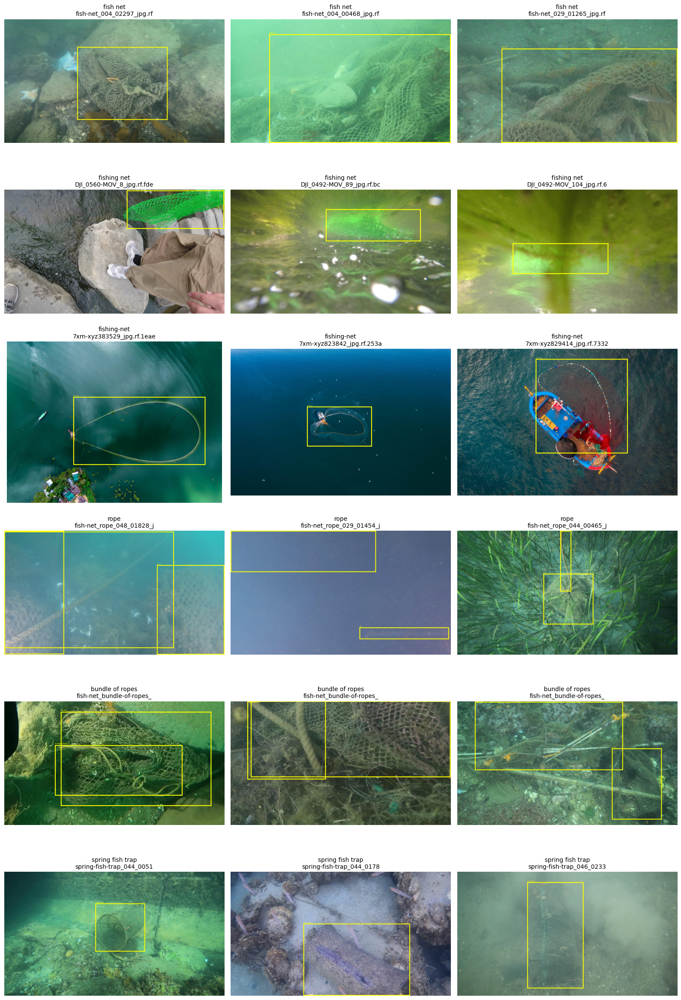

Saved: /content/drive/MyDrive/MarineGuard_Validation_Improvement/roboflow_class_visual_audit.png


In [12]:

from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt
from collections import defaultdict
import yaml
import random

ROOT = Path(
    "/content/drive/MyDrive/MarineGuard_Roboflow_FishingNet_v3"
)
DATA = next(ROOT.rglob("data.yaml")).parent

with open(DATA / "data.yaml") as f:
    cfg = yaml.safe_load(f)

names = cfg["names"]
if isinstance(names, list):
    names = dict(enumerate(names))
else:
    names = {int(k): v for k, v in names.items()}

# Five target-related classes + one comparison class
inspect_classes = [
    "fish net",
    "fishing net",
    "fishing-net",
    "rope",
    "bundle of ropes",
    "spring fish trap"
]

class_ids = {
    name: cls
    for cls, name in names.items()
}

samples_by_class = defaultdict(list)

# Use training images only for this inspection
image_dir = DATA / "train" / "images"
label_dir = DATA / "train" / "labels"

for img in sorted(image_dir.iterdir()):
    if img.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        continue

    label = label_dir / f"{img.stem}.txt"
    if not label.exists():
        continue

    lines = label.read_text().splitlines()

    present = set()
    for line in lines:
        parts = line.split()
        if len(parts) == 5:
            present.add(int(parts[0]))

    for name in inspect_classes:
        if class_ids[name] in present:
            samples_by_class[name].append((img, label))

random.seed(42)

fig, axes = plt.subplots(
    len(inspect_classes), 3,
    figsize=(16, 24)
)

for row, class_name in enumerate(inspect_classes):

    candidates = samples_by_class[class_name]
    selected = random.sample(
        candidates, min(3, len(candidates))
    )

    for col in range(3):
        ax = axes[row, col]
        ax.axis("off")

        if col >= len(selected):
            continue

        img_path, label_path = selected[col]

        image = Image.open(img_path).convert("RGB")
        w, h = image.size
        draw = ImageDraw.Draw(image)

        for line in label_path.read_text().splitlines():
            parts = line.split()

            if len(parts) != 5:
                continue

            cls = int(parts[0])
            xc, yc, bw, bh = map(float, parts[1:])

            x1 = (xc - bw / 2) * w
            y1 = (yc - bh / 2) * h
            x2 = (xc + bw / 2) * w
            y2 = (yc + bh / 2) * h

            # Target classes yellow, others red
            color = (
                "yellow" if names[cls] in inspect_classes
                else "red"
            )

            draw.rectangle(
                (x1, y1, x2, y2),
                outline=color,
                width=max(2, w // 250)
            )

            draw.text(
                (max(0, x1), max(0, y1 - 15)),
                names[cls],
                fill=color
            )

        ax.imshow(image)
        ax.set_title(
            f"{class_name}\n{img_path.name[:25]}",
            fontsize=10
        )

plt.tight_layout()

OUTPUT = Path(
    "/content/drive/MyDrive/"
    "MarineGuard_Validation_Improvement"
)
OUTPUT.mkdir(parents=True, exist_ok=True)

plt.savefig(
    OUTPUT / "roboflow_class_visual_audit.png",
    dpi=140,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved:",
    OUTPUT / "roboflow_class_visual_audit.png"
)


## 12 | Target Net-image inspection

Inspect a larger sample of the candidate “fish net” category and its co-occurring annotations before deciding whether the dataset is appropriate for integration.


Images containing 'fish net': 630

Other annotations in these images:
  bundle of ropes: 28
  rope: 11
  eel fish trap: 3
  other objects: 3
  tire: 3
  circular fish trap: 2
  wood: 2
  spring fish trap: 1


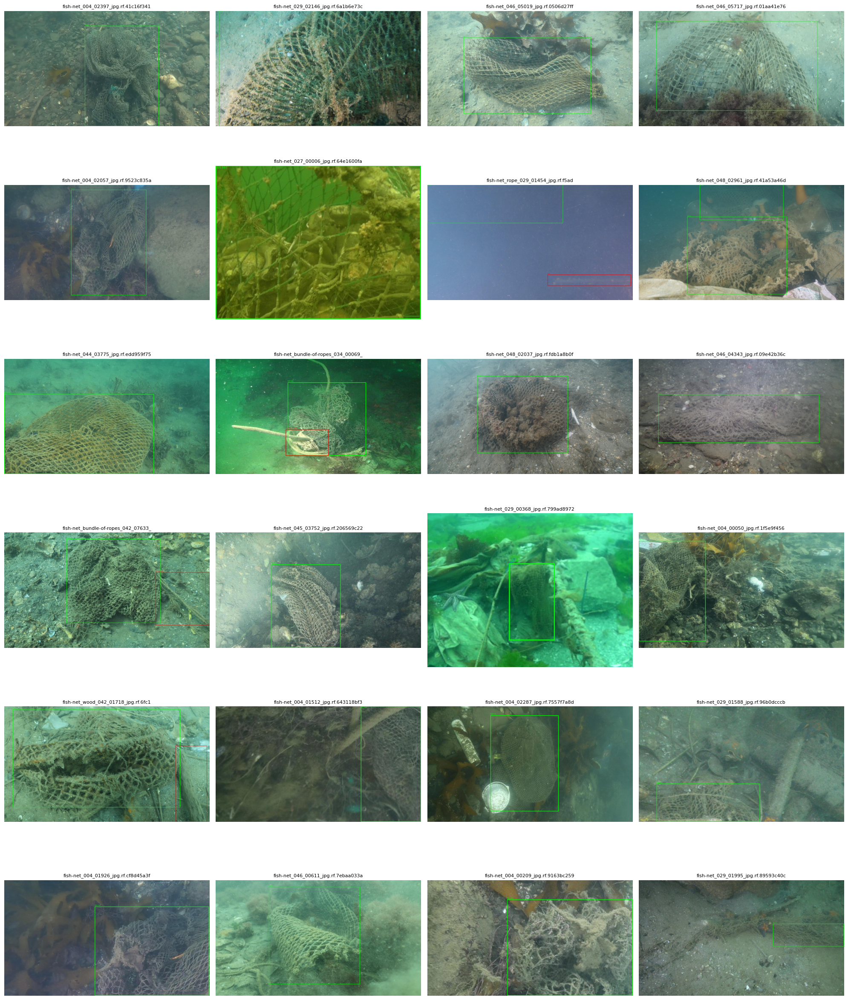


Saved 24-image review to: /content/drive/MyDrive/MarineGuard_Validation_Improvement


In [13]:

from pathlib import Path
from collections import Counter
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import random
import yaml

ROOT = Path(
    "/content/drive/MyDrive/MarineGuard_Roboflow_FishingNet_v3/"
    "fishing-net-detection.v3i.yolov8"
)

with open(ROOT / "data.yaml") as f:
    cfg = yaml.safe_load(f)

names = cfg["names"]
if isinstance(names, list):
    names = dict(enumerate(names))
else:
    names = {int(k): v for k, v in names.items()}

NET_ID = 3  # "fish net" only

image_dir = ROOT / "train/images"
label_dir = ROOT / "train/labels"

candidates = []
other_classes = Counter()

for image_path in sorted(image_dir.iterdir()):
    if image_path.suffix.lower() not in {
        ".jpg", ".jpeg", ".png"
    }:
        continue

    label_path = label_dir / f"{image_path.stem}.txt"

    if not label_path.exists():
        continue

    annotations = []

    for line in label_path.read_text().splitlines():
        parts = line.split()

        if len(parts) != 5:
            continue

        cls = int(parts[0])
        coords = tuple(map(float, parts[1:]))

        annotations.append((cls, coords))

    if any(cls == NET_ID for cls, _ in annotations):
        candidates.append((image_path, annotations))

        for cls, _ in annotations:
            if cls != NET_ID:
                other_classes[names[cls]] += 1

print("Images containing 'fish net':", len(candidates))
print("\nOther annotations in these images:")

for name, count in other_classes.most_common():
    print(f"  {name}: {count}")

random.seed(2026)
samples = random.sample(
    candidates,
    min(24, len(candidates))
)

fig, axes = plt.subplots(6, 4, figsize=(20, 25))

for ax in axes.flat:
    ax.axis("off")

for ax, (path, annotations) in zip(axes.flat, samples):
    with Image.open(path) as im:
        image = im.convert("RGB")

    w, h = image.size
    draw = ImageDraw.Draw(image)

    for cls, (xc, yc, bw, bh) in annotations:
        x1 = (xc - bw / 2) * w
        y1 = (yc - bh / 2) * h
        x2 = (xc + bw / 2) * w
        y2 = (yc + bh / 2) * h

        color = "lime" if cls == NET_ID else "red"

        draw.rectangle(
            (x1, y1, x2, y2),
            outline=color,
            width=3
        )

        draw.text(
            (max(0, x1), max(0, y1 - 15)),
            names[cls],
            fill=color
        )

    ax.imshow(image)
    ax.set_title(
        path.name[:35],
        fontsize=8
    )

plt.tight_layout()

OUTPUT = Path(
    "/content/drive/MyDrive/"
    "MarineGuard_Validation_Improvement"
)

OUTPUT.mkdir(parents=True, exist_ok=True)

plt.savefig(
    OUTPUT / "roboflow_fish_net_24_samples.png",
    dpi=140,
    bbox_inches="tight"
)

plt.show()

print("\nSaved 24-image review to:", OUTPUT)


## Summary and interpretation

The provenance and annotation audit supports the consistency of the **SeaClear-derived** YOLO labels with the original COCO records. It also identifies a major evaluation limitation: SeaClear Net instances are concentrated in Bistrina, and the original validation subset contains only seven annotated Nets from one camera recording.

The camera-holdout calculation is a **proposal**, not a replacement for the final dataset manifest. The Roboflow review is a **candidate-source assessment**; those images were not added to the selected model. The final MarineGuard AI Version 1 demonstration retains the original YOLO26n checkpoint, with limitations and later cross-camera findings documented separately.
